# Classifying high-priced Airbnb listings in New York City

This notebook compares a tuned decision tree with a small neural network for classifying listings as **high** or **low** price. In this dataset, `price_category` is derived from the listed `price`; the high category starts at $180. The model uses listing attributes and excludes `price` to avoid direct target leakage.

The experiment is a classification exercise on a fixed historical dataset. It does not estimate a listing's price, predict future revenue, or provide an investment recommendation. Run the cells from top to bottom to regenerate the results.


## 1. Load data and reserve a test set

The raw CSV has 28,022 listings and 51 columns. The label is imbalanced, so high-class F1 is the main model selection metric. Accuracy, precision, and recall provide context. The listed price and personal text fields are excluded before modeling. We split before exploratory analysis so the plots and summaries below use training rows only.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
sns.set_theme(style="whitegrid")


data_path = Path("../data/airbnbListingsData.csv")

df = pd.read_csv(data_path)

print(f"Listings: {len(df):,}; columns: {df.shape[1]}")
df.head()


Listings: 28,022; columns: 51


,name,description,neighborhood_overview,host_name,host_location,host_about,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,...,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,n_host_verifications,price_category
0,Skylit Midtown Castle,"Beautiful, spacious skylit studio in the heart...",Centrally located in the heart of Manhattan ju...,Jennifer,"New York, New York, United States",A New Yorker since 2000! My passion is creatin...,0.80,0.17,True,8.0,...,4.86,4.41,False,3,3,0,0,0.33,9,low
1,"Whole flr w/private bdrm, bath & kitchen(pls r...","Enjoy 500 s.f. top floor in 1899 brownstone, w...",Just the right mix of urban center and local n...,LisaRoxanne,"New York, New York, United States",Laid-back Native New Yorker (formerly bi-coast...,0.09,0.69,True,1.0,...,4.71,4.64,False,1,1,0,0,4.86,6,low
2,"Spacious Brooklyn Duplex, Patio + Garden",We welcome you to stay in our lovely 2 br dupl...,NaN,Rebecca,"Brooklyn, New York, United States","Rebecca is an artist/designer, and Henoch is i...",1.00,0.25,True,1.0,...,4.50,5.00,False,1,1,0,0,0.02,3,high
3,Large Furnished Room Near B'way,Please don’t expect the luxury here just a bas...,"Theater district, many restaurants around here.",Shunichi,"New York, New York, United States",I used to work for a financial industry but no...,1.00,1.00,True,1.0,...,4.87,4.36,False,1,0,1,0,3.68,4,low
4,Cozy Clean Guest Room - Family Apt,"Our best guests are seeking a safe, clean, spa...",Our neighborhood is full of restaurants and ca...,MaryEllen,"New York, New York, United States",Welcome to family life with my oldest two away...,NaN,NaN,True,1.0,...,4.94,4.92,False,1,0,1,0,0.87,7,low


In [2]:
columns_to_drop = [
    "name", "description", "neighborhood_overview", "host_about",
    "host_name", "host_location", "amenities", "host_total_listings_count",
    "price", "price_category",
]

if set(df["price_category"].unique()) != {"low", "high"}:
    raise ValueError("Expected only 'low' and 'high' price categories")

y = df["price_category"].map({"low": 0, "high": 1})
X = df.drop(columns=columns_to_drop).copy()
boolean_features = X.select_dtypes(include="bool").columns
X = X.astype({column: "int8" for column in boolean_features})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()
if len(numeric_features) + len(categorical_features) != X.shape[1]:
    raise TypeError("An input feature has an unsupported dtype")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Numeric features: {len(numeric_features)}; categorical features: {len(categorical_features)}")


Training rows: 22,417; test rows: 5,605
Numeric features: 39; categorical features: 2


## 2. Explore training data

The target uses `high = 1`. The positive-class share and missing-value summary below come only from the training split.

price_category
low     16628
high     5789
High-price share in training data: 25.8%


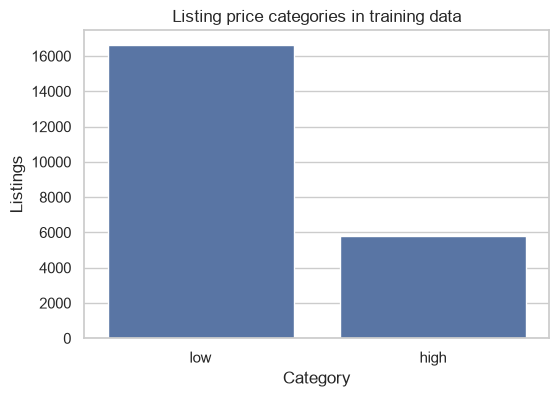

In [3]:
label_counts = y_train.value_counts().reindex([0, 1])
print(label_counts.rename(index={0: "low", 1: "high"}).to_string())
print(f"High-price share in training data: {label_counts[1] / label_counts.sum():.1%}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["low", "high"], y=label_counts.values, ax=ax)
ax.set(title="Listing price categories in training data", xlabel="Category", ylabel="Listings")
plt.show()


In [4]:
missing_share = X_train.isna().mean().sort_values(ascending=False)
missing_share[missing_share > 0].head(12).rename("Missing share")


host_response_rate      0.425481
host_acceptance_rate    0.398938
bedrooms                0.104073
beds                    0.048713
Name: Missing share, dtype: float64

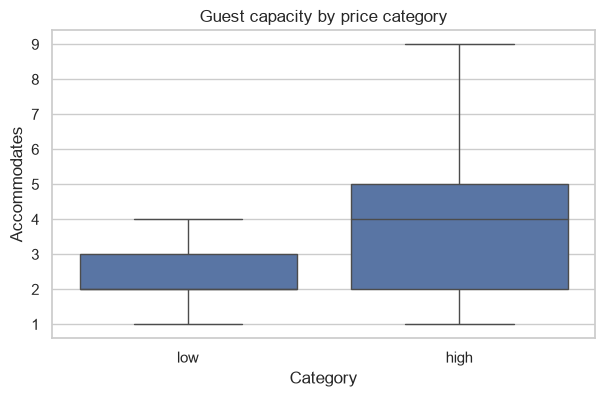

In [5]:
training_view = X_train.assign(price_category=y_train.map({0: "low", 1: "high"}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=training_view, x="price_category", y="accommodates",
            order=["low", "high"], showfliers=False, ax=ax)
ax.set(title="Guest capacity by price category", xlabel="Category", ylabel="Accommodates")
plt.show()


The training data has missing values in several host and property fields. Host listing counts have a long tail, and the source contains eight records with `minimum_nights` above 365. These records remain because the original model did not filter them. These choices define this experiment rather than a general production data policy.

## 3. Build leakage-aware preprocessing

Numeric missing values are imputed by the median, and categorical values are one hot encoded. The tree pipeline fits these transformations separately within each cross-validation training fold. The test rows remain outside model selection.

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features),
    ],
    verbose_feature_names_out=False,
)


## 4. Tune the decision tree

Five-fold stratified cross-validation selects tree depth and minimum node sizes using positive-class F1. Imputation and encoding are fitted separately within each training fold. The final estimator is refitted on all training rows.

In [7]:
tree_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", DecisionTreeClassifier(random_state=SEED)),
])

parameter_grid = {
    "model__max_depth": [10, 15, 20, 30],
    "model__min_samples_split": [10, 20, 50],
    "model__min_samples_leaf": [5, 25, 50],
}

search = GridSearchCV(
    tree_pipeline,
    param_grid=parameter_grid,
    scoring="f1",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    refit=True,
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Mean cross-validation F1: {search.best_score_:.4f}")

tree_predictions = search.predict(X_test)


Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__min_samples_split': 50}
Mean cross-validation F1: 0.6453


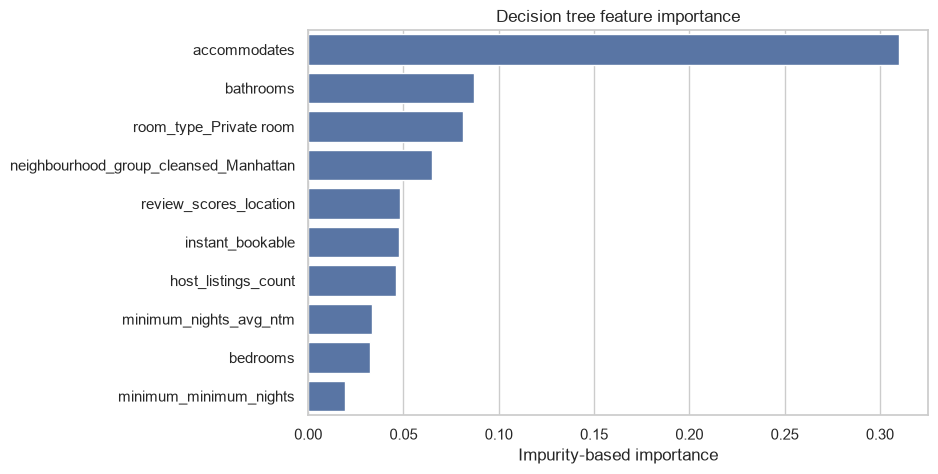

In [8]:
feature_names = search.best_estimator_.named_steps["preprocess"].get_feature_names_out()
feature_importance = pd.Series(
    search.best_estimator_.named_steps["model"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=feature_importance.head(10).values,
            y=feature_importance.head(10).index, ax=ax)
ax.set(title="Decision tree feature importance", xlabel="Impurity-based importance", ylabel="")
plt.show()


Tree importance describes how this fitted tree used features. It does not establish a causal effect or explain each prediction. Correlated features can also split importance between them.

## 5. Train the neural network

A second stratified split reserves validation rows from the training set. Imputation, encoding, and scaling are fitted only on the neural network's training subset. The network uses the original two hidden layers (64 and 32 ReLU units) and a sigmoid output. Early stopping restores the weights with the lowest validation loss.

In [9]:
X_nn_train, X_nn_valid, y_nn_train, y_nn_valid = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED
)

nn_preprocessor = clone(preprocessor)
X_nn_train_encoded = nn_preprocessor.fit_transform(X_nn_train)
X_nn_valid_encoded = nn_preprocessor.transform(X_nn_valid)
X_nn_test_encoded = nn_preprocessor.transform(X_test)

scaler = StandardScaler()
X_nn_train_scaled = scaler.fit_transform(X_nn_train_encoded).astype("float32")
X_nn_valid_scaled = scaler.transform(X_nn_valid_encoded).astype("float32")
X_nn_test_scaled = scaler.transform(X_nn_test_encoded).astype("float32")

print(f"Encoded input features: {X_nn_train_scaled.shape[1]}")


Encoded input features: 48


In [10]:
tf.keras.utils.set_random_seed(SEED)
network = tf.keras.Sequential([
    tf.keras.Input(shape=(X_nn_train_scaled.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
network.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history = network.fit(
    X_nn_train_scaled,
    y_nn_train.to_numpy(),
    validation_data=(X_nn_valid_scaled, y_nn_valid.to_numpy()),
    epochs=20,
    batch_size=32,
    verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )],
)
print(f"Epochs trained: {len(history.history['loss'])}")


Epochs trained: 20


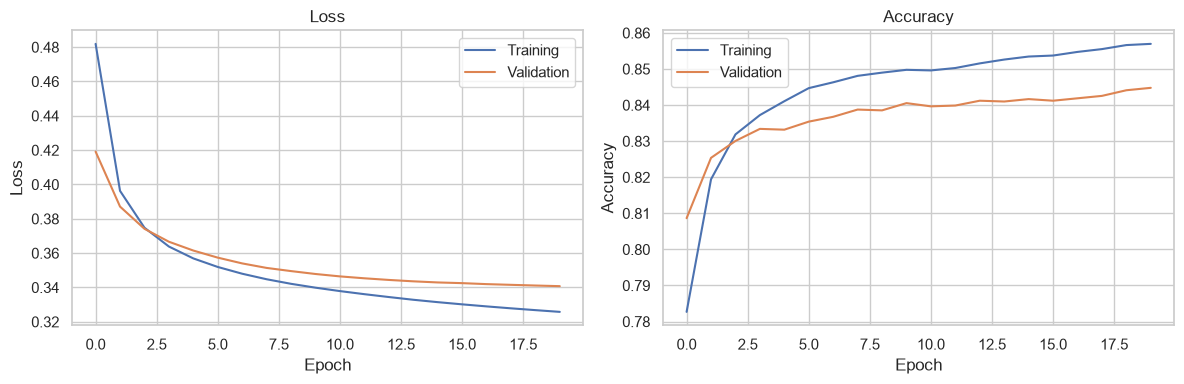

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history.history[metric], label="Training")
    ax.plot(history.history[f"val_{metric}"], label="Validation")
    ax.set(title=metric.capitalize(), xlabel="Epoch", ylabel=metric.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

network_probabilities = network.predict(X_nn_test_scaled, verbose=0).ravel()
network_predictions = (network_probabilities >= 0.5).astype(int)


## 6. Compare held-out performance

Both models use the same untouched test rows. F1 emphasizes the high-price class; precision and recall show the two kinds of classification error. The grid search score above is a cross-validation score on training data, while the table below reports final test scores.

In [12]:
def classification_metrics(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision (high)": precision_score(actual, predicted, zero_division=0),
        "Recall (high)": recall_score(actual, predicted, zero_division=0),
        "F1 (high)": f1_score(actual, predicted, zero_division=0),
    }

results = pd.DataFrame.from_dict({
    "Decision tree": classification_metrics(y_test, tree_predictions),
    "Neural network": classification_metrics(y_test, network_predictions),
}, orient="index")
results.round(4)


,Accuracy,Precision (high),Recall (high),F1 (high)
Decision tree,0.8282,0.7033,0.5794,0.6354
Neural network,0.8412,0.7491,0.5794,0.6534


## Interpretation and limitations

The final model should be selected based on the test results and the types of errors that matter most. Since the neural network requires more training time and preprocessing, a small improvement in performance may not be worth the extra complexity.

There are also some limitations to consider. Both models were tested on the current dataset, so we don't know how well they would perform on newer Airbnb listings or data from other sources. The model predicts whether a listing is relatively expensive or affordable within this dataset. It does not predict listing quality, rental income, or future prices.

Factors like location and host activity may also influence predictions in ways that disadvantage certain neighborhoods or newer hosts. We haven't tested whether the model performs equally well across different groups. Before using it in a real-world application, we would need to understand the data source, consider the impact of incorrect predictions, and test the model on newer data.